# Wasserstein Practical-Significance Test for a 2-D Output: Type I Error and Power

**Setup.** Candidate $F_t$ = bivariate normal (mean `MU`, sds `SD_F`, correlation `RHO_F`); true system $G_t$ = bivariate normal
(mean `MU + SHIFT`, sds `SD_G`, correlation `RHO_G`). Each period gives one observation $\mathbf y_t\sim G_t$ and $R$ replications from $F_t$.

**Rosenblatt estimates** (same estimator as the bivariate tandem notebook). A bivariate Gaussian KDE (Silverman) is fitted to the $R$ replications, giving
$\widehat F_{t,1}$ and $\widehat F_{t,2\mid1}(\cdot\mid y_{t1})$ as Gaussian mixtures with closed forms.

**PIT box.** For $\boldsymbol\delta=(\delta_1,\delta_2)$, each coordinate gets
$[\underline U_{t,j},\overline U_{t,j}]$ from the paper's $y^\pm_{t}(\delta_j)$ formulas, found by bisection on the transport cost
$\int_y^{y_t}(y_t-h)\hat f(h)\,dh$ (closed form for a Gaussian mixture). The box is the product of the two intervals.

**Statistic.** $W(\mathbf U)$ is $W_2$ between the $T$ points and a fixed $T$-point Halton reference $\{v_i\}$ (Hungarian matching), as in the tandem notebook.
$c_\alpha^{(2)}$ is its $(1-\alpha)$ quantile for $T$ iid $U([0,1]^2)$ points.
For a fixed matching, the best point in box $t$ is $v_i$ clipped into the box, so
$W^{\star,(2)}(\boldsymbol\delta)^2=\min_\sigma \frac1T\sum_t \operatorname{dist}(v_{\sigma(t)},\text{box}_t)^2$: this is an exact assignment problem.

**Output.** Reject $H_0(\boldsymbol\delta)$ if $W^{\star,(2)}(\boldsymbol\delta)>c^{(2)}_\alpha$. The rejection rate on a $\delta_1\times\delta_2$ grid is a
Type I error where $H_0$ holds and power elsewhere. $H_0$ is judged against the true $W_1$ values (marginal, and conditional given $y_{t1}$);
these ignore the KDE's own smoothing and Monte Carlo error.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.optimize import linear_sum_assignment
from scipy.special import ndtr
from scipy.stats import norm, gaussian_kde, qmc
from joblib import Parallel, delayed


def npdf(z):
    return np.exp(-0.5 * z * z) / np.sqrt(2 * np.pi)


def rosenblatt_mixtures(y1, S1, S2):
    # For every t: F_hat_1 and F_hat_{2|1}(. | y_t1) as Gaussian mixtures (weights w, means m, common sd s).
    # S1, S2: (T, R) replications of output 1 and output 2.
    T, R = S1.shape
    w2, m2, s1, s2 = np.empty((T, R)), np.empty((T, R)), np.empty(T), np.empty(T)
    for t in range(T):
        H = gaussian_kde(np.vstack([S1[t], S2[t]]), bw_method="silverman").covariance
        s1[t] = np.sqrt(H[0, 0])
        k = npdf((y1[t] - S1[t]) / s1[t])
        w2[t] = k / k.sum() if k.sum() > 0 else 1 / R
        m2[t] = S2[t] + H[0, 1] / H[0, 0] * (y1[t] - S1[t])
        s2[t] = np.sqrt(H[1, 1] - H[0, 1] ** 2 / H[0, 0])
    return (np.full((T, R), 1 / R), S1, s1), (w2, m2, s2)


def pit_bounds(y, mix, delta, iters=40):
    # [inf F(y_t), sup F(y_t)] over the W1 ball of radius delta around the mixture F_hat_t (vectorised over t)
    w, m, s = mix
    S, Y = s[:, None], y[:, None]
    cdf = lambda x: (w * ndtr((x[:, None] - m) / S)).sum(1)
    if delta == 0:
        F = cdf(y)
        return F, F
    zy = (Y - m) / S
    Fy, py = ndtr(zy), npdf(zy)
    cost_lo = lambda a: (w * ((Y - m) * (Fy - ndtr((a[:, None] - m) / S)) + S * (py - npdf((a[:, None] - m) / S)))).sum(1)
    cost_hi = lambda b: (w * ((m - Y) * (ndtr((b[:, None] - m) / S) - Fy) + S * (py - npdf((b[:, None] - m) / S)))).sum(1)

    a_lo, a_hi = m.min(1) - 12 * s, y.copy()          # y^- : smallest a <= y_t with cost_lo(a) <= delta
    b_lo, b_hi = y.copy(), m.max(1) + 12 * s          # y^+ : largest  b >= y_t with cost_hi(b) <= delta
    for _ in range(iters):
        a = (a_lo + a_hi) / 2
        over = cost_lo(a) > delta
        a_lo, a_hi = np.where(over, a, a_lo), np.where(over, a_hi, a)
        b = (b_lo + b_hi) / 2
        over = cost_hi(b) > delta
        b_lo, b_hi = np.where(over, b_lo, b), np.where(over, b, b_hi)
    return cdf(a_hi), cdf(b_lo)   # F(y^-), F(y^+)


def w2_stat(U, ref):
    # W2 between the T points U and the T-point reference (Hungarian matching)
    C = ((U[:, None, :] - ref[None, :, :]) ** 2).sum(2)
    r, c = linear_sum_assignment(C)
    return np.sqrt(C[r, c].mean())


def w_star(lo, hi, ref, return_points=False):
    # min of w2_stat over U_t in the box [lo_t, hi_t]; for a fixed matching the best U_t is ref_i clipped into box t
    P = np.clip(ref[None, :, :], lo[:, None, :], hi[:, None, :])   # P[t, i] = projection of ref_i onto box t
    C = ((P - ref[None, :, :]) ** 2).sum(2)
    r, c = linear_sum_assignment(C)
    val = np.sqrt(C[r, c].mean())
    return (val, P[r, c]) if return_points else val


def w1_normals(a, s1, b, s2):
    # W1(N(a, s1^2), N(b, s2^2)) = E|(a - b) + (s1 - s2) Z|
    d, s = a - b, abs(s1 - s2)
    return np.abs(d) if s == 0 else d * (2 * norm.cdf(d / s) - 1) + 2 * s * norm.pdf(d / s)


def bivariate_normal(mean, sd, rho, size, rng):
    cov = np.array([[sd[0] ** 2, rho * sd[0] * sd[1]], [rho * sd[0] * sd[1], sd[1] ** 2]])
    return rng.multivariate_normal(mean, cov, size=size)

In [5]:
# ---- candidate (simulation) model:  F_t = bivariate normal, same in every period
T = 100                        # historical periods
R = 200                        # simulation replications per period
MU = np.array([2.0, 2.0])      # candidate mean (output 1, output 2)
SD_F = np.array([1.0, 1.0])
RHO_F = 0.5

# ---- true system:  G_t = bivariate normal with mean MU + SHIFT
SHIFT = np.array([2, 0.0])
SD_G = np.array([1.0, 1.0])
RHO_G = 0.5

# ---- test settings
ALPHA = 0.05
M = 300                                          # simulated histories
DELTA_GRID = [0, 0.01, 0.02, 0.05, 0.1, 0.25, 0.5]   # used for both delta_1 and delta_2
SHOW_DELTA = (0.02, 0.02)                        # (delta_1, delta_2) shown in the PIT-box plot
SEED = 0

c_alpha = 0.1154    true W1: output 1 = 2.000,  output 2 | output 1 = 1.000
H0(delta) is true where delta_1 >= output-1 value and delta_2 >= output-2 value.



delta_2,0.00,0.01,0.02,0.05,0.10,0.25,0.50
delta_1,,,,,,,
0.00,1.0,1.0,1.0,1.000,1.000,1.000,1.000
0.01,1.0,1.0,1.0,1.000,1.000,1.000,1.000
0.02,1.0,1.0,1.0,1.000,1.000,1.000,1.000
0.05,1.0,1.0,1.0,1.000,1.000,1.000,1.000
0.10,1.0,1.0,1.0,1.000,1.000,1.000,1.000
0.25,1.0,1.0,1.0,1.000,1.000,0.997,0.997
0.50,1.0,1.0,1.0,0.983,0.577,0.017,0.007


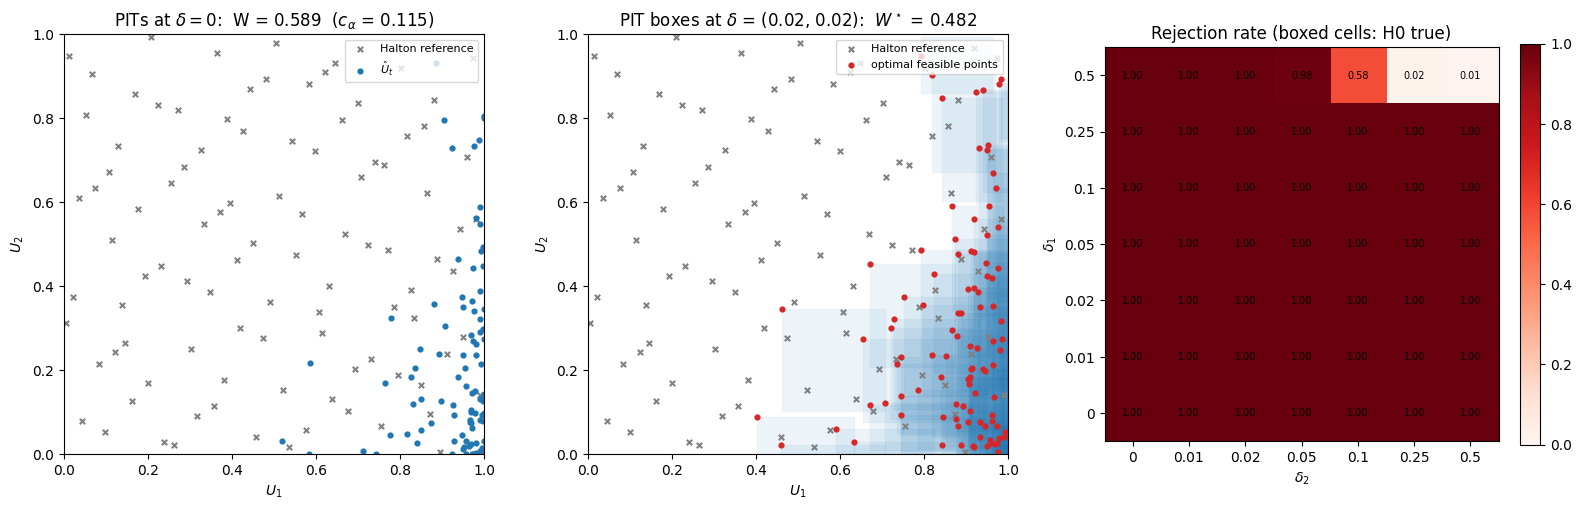

In [6]:
rng = np.random.default_rng(SEED)
REF = qmc.Halton(d=2, seed=SEED).random(T)
c_alpha = np.quantile([w2_stat(rng.random((T, 2)), REF) for _ in range(5000)], 1 - ALPHA)


def simulate(seed):
    g = np.random.default_rng(seed)
    y = bivariate_normal(MU + SHIFT, SD_G, RHO_G, T, g)                          # observed y_t ~ G_t, (T, 2)
    Ysim = bivariate_normal(MU, SD_F, RHO_F, T * R, g).reshape(T, R, 2)          # replications from F_t
    return y, rosenblatt_mixtures(y[:, 0], Ysim[..., 0], Ysim[..., 1])


def one_history(seed):
    y, (mix1, mix2) = simulate(seed)
    B1 = [pit_bounds(y[:, 0], mix1, d) for d in DELTA_GRID]
    B2 = [pit_bounds(y[:, 1], mix2, d) for d in DELTA_GRID]
    return np.array([[w_star(np.column_stack([b1[0], b2[0]]), np.column_stack([b1[1], b2[1]]), REF)
                      for b2 in B2] for b1 in B1])


W = np.array(Parallel(n_jobs=-1)(delayed(one_history)(SEED + 1 + i) for i in range(M)))   # (M, n_delta, n_delta)
reject = (W > c_alpha).mean(0)

# ---- true discrepancies: marginal of output 1, and conditional of output 2 given y_t1 (max over t, first history)
y0, _ = simulate(SEED + 1)
true_d1 = w1_normals(MU[0] + SHIFT[0], SD_G[0], MU[0], SD_F[0])
cond_mean_G = MU[1] + SHIFT[1] + RHO_G * SD_G[1] / SD_G[0] * (y0[:, 0] - MU[0] - SHIFT[0])
cond_mean_F = MU[1] + RHO_F * SD_F[1] / SD_F[0] * (y0[:, 0] - MU[0])
true_d2 = max(w1_normals(a, SD_G[1] * np.sqrt(1 - RHO_G**2), b, SD_F[1] * np.sqrt(1 - RHO_F**2))
              for a, b in zip(cond_mean_G, cond_mean_F))
print(f"c_alpha = {c_alpha:.4f}    true W1: output 1 = {true_d1:.3f},  output 2 | output 1 = {true_d2:.3f}")
print("H0(delta) is true where delta_1 >= output-1 value and delta_2 >= output-2 value.\n")

table = pd.DataFrame(reject, index=pd.Index(DELTA_GRID, name="delta_1"), columns=pd.Index(DELTA_GRID, name="delta_2"))
display(table.round(3))

# ---- figures (first history)
y, (mix1, mix2) = simulate(SEED + 1)
U0 = np.column_stack([pit_bounds(y[:, 0], mix1, 0)[0], pit_bounds(y[:, 1], mix2, 0)[0]])
l1, h1 = pit_bounds(y[:, 0], mix1, SHOW_DELTA[0])
l2, h2 = pit_bounds(y[:, 1], mix2, SHOW_DELTA[1])
lo, hi = np.column_stack([l1, l2]), np.column_stack([h1, h2])
ws, U_opt = w_star(lo, hi, REF, return_points=True)

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
ax[0].scatter(*REF.T, marker="x", c="gray", s=15, label="Halton reference")
ax[0].scatter(*U0.T, s=12, c="C0", label=r"$\hat U_t$")
ax[0].set_title(rf"PITs at $\delta=0$:  W = {w2_stat(U0, REF):.3f}  ($c_\alpha$ = {c_alpha:.3f})")

for (a, b), (c, d) in zip(lo, hi):
    ax[1].add_patch(Rectangle((a, b), c - a, d - b, fc="C0", alpha=0.08, ec="C0", lw=0.3))
ax[1].scatter(*REF.T, marker="x", c="gray", s=15, label="Halton reference")
ax[1].scatter(*U_opt.T, s=12, c="C3", label="optimal feasible points")
ax[1].set_title(rf"PIT boxes at $\delta$ = {SHOW_DELTA}:  $W^\star$ = {ws:.3f}")
for a in ax[:2]:
    a.set(xlim=(0, 1), ylim=(0, 1), xlabel=r"$U_1$", ylabel=r"$U_2$", aspect="equal")
    a.legend(loc="upper right", fontsize=8)

im = ax[2].imshow(reject, origin="lower", cmap="Reds", vmin=0, vmax=1)
n = len(DELTA_GRID)
ax[2].set(xticks=range(n), yticks=range(n), xticklabels=DELTA_GRID, yticklabels=DELTA_GRID,
          xlabel=r"$\delta_2$", ylabel=r"$\delta_1$", title="Rejection rate (boxed cells: H0 true)")
for i, d1 in enumerate(DELTA_GRID):
    for j, d2 in enumerate(DELTA_GRID):
        ax[2].text(j, i, f"{reject[i, j]:.2f}", ha="center", va="center", fontsize=7)
        if d1 >= true_d1 - 1e-9 and d2 >= true_d2 - 1e-9:
            ax[2].add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="k", lw=1.5))
fig.colorbar(im, ax=ax[2], fraction=0.046)
plt.tight_layout()
plt.show()